In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una empresa constructora ejecuta como contratista principal el proyecto cuyo cuadro de prelaciones, duraciones (semanas) y operarios necesarios por actividad se adjunta. La plantilla propia disponible es de **5 operarios**; cada operario-semana propio cuesta 2.0 k€, uno contratado a través de una empresa de trabajo temporal (ETT) 2.6 k€ y el retraso del proyecto tiene una penalidad de 8 k€ por semana.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, resources
    ('A'     , '---'      , 3       , 1        ),
    ('B'     , '---'      , 5       , 1        ),
    ('C'     , 'B'        , 5       , 4        ),
    ('D'     , 'A,C'      , 6       , 4        ),
    ('E'     , 'B'        , 1       , 3        ),
    ('F'     , 'C'        , 2       , 4        ),
    ('G'     , 'E,F'      , 2       , 4        ),
    ('H'     , 'D,G'      , 4       , 2        ),
    ('I'     , 'E,F'      , 1       , 2        ),
], columns=['activity', 'predecessor', 'duration', 'resources']).set_index('activity')
datos_enunciado

,predecessor,duration,resources
activity,,,
A,---,3,1
B,---,5,1
C,B,5,4
D,"A,C",6,4
E,B,1,3
F,C,2,4
G,"E,F",2,4
H,"D,G",4,2
I,"E,F",1,2


> **De: Director de producción**
> Para las semanas de pico no contratamos a nadie: lo subcontratamos a la empresa de siempre, que a su vez lo pasa a su subcontrata, esta a una tercera y esta a las cuadrillas de autónomos, que es donde está el precio: 1.6 k€ por operario-semana, menos que los nuestros. Cuatro escalones, pero a nosotros nos factura uno solo y el Libro de Subcontratación lo llevan ellos.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S10 — Condiciones de trabajo en la cadena de ejecución.** El plan no puede apoyarse en condiciones de trabajo que la norma prohíbe: ni en una cadena de subcontratación más larga que la permitida, ni en jornadas al aire libre que ignoren los avisos por calor extremo. Una ventaja de coste o plazo obtenida así no es una opción de la tabla (cf. C7 y C5 de la lección 19). *(cf. Ley 32/2006 de subcontratación en la construcción, arts. 4 y 5; RD 486/1997, disposición adicional única (RDL 4/2023); ICB4, Perspectiva 3 «salud, seguridad y medio ambiente».)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **Norma o dato de referencia — en las obras de construcción el contratista puede subcontratar con un primer subcontratista, este con un segundo y este con un tercero; el tercer subcontratista y los trabajadores autónomos no pueden subcontratar. Excepcionalmente (caso fortuito, especialización, fuerza mayor) la dirección facultativa puede aprobar un nivel más, que se anota en el Libro de Subcontratación. Las empresas que se dedican habitualmente a contratar o subcontratar obras deben tener al menos un 30 % de plantilla indefinida** *(Ley 32/2006, arts. 5.2, 5.3 y 4.4.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga el pico y el exceso de operarios sobre los 5 de plantilla, semana a semana. Nivele las cargas dentro de las holguras (nivelación) y repita el cálculo: ¿cuántos operarios-semana de exceso quedan?  "
pregunta_2 = "2. (A) Calcule el coste de cubrir el exceso (tras nivelar) con la cadena de subcontratas y con una ETT, y el coste de no cubrirlo: asignación con límite de 5 operarios, retraso y penalidad. ¿Cuál es la opción más barata y cuánto vale el «ahorro» de la cadena?  "
pregunta_3 = "3. (B) Según la norma y el criterio de referencia, ¿puede ejecutarse la propuesta del director de producción? ¿Cuál es el último nivel que puede subcontratar y en qué condiciones se admite uno más?  "
pregunta_4 = "4. (C) ¿Qué propone al director de producción? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga el pico y el exceso de operarios sobre los 5 de plantilla, semana a semana. Nivele las cargas dentro de las holguras (nivelación) y repita el cálculo: ¿cuántos operarios-semana de exceso quedan?  

2. (A) Calcule el coste de cubrir el exceso (tras nivelar) con la cadena de subcontratas y con una ETT, y el coste de no cubrirlo: asignación con límite de 5 operarios, retraso y penalidad. ¿Cuál es la opción más barata y cuánto vale el «ahorro» de la cadena?  

3. (B) Según la norma y el criterio de referencia, ¿puede ejecutarse la propuesta del director de producción? ¿Cuál es el último nivel que puede subcontratar y en qué condiciones se admite uno más?  

4. (C) ¿Qué propone al director de producción? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
plantilla, coste_propio, coste_ett, coste_cadena, penalidad = 5, 2.0, 2.6, 1.6, 8
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

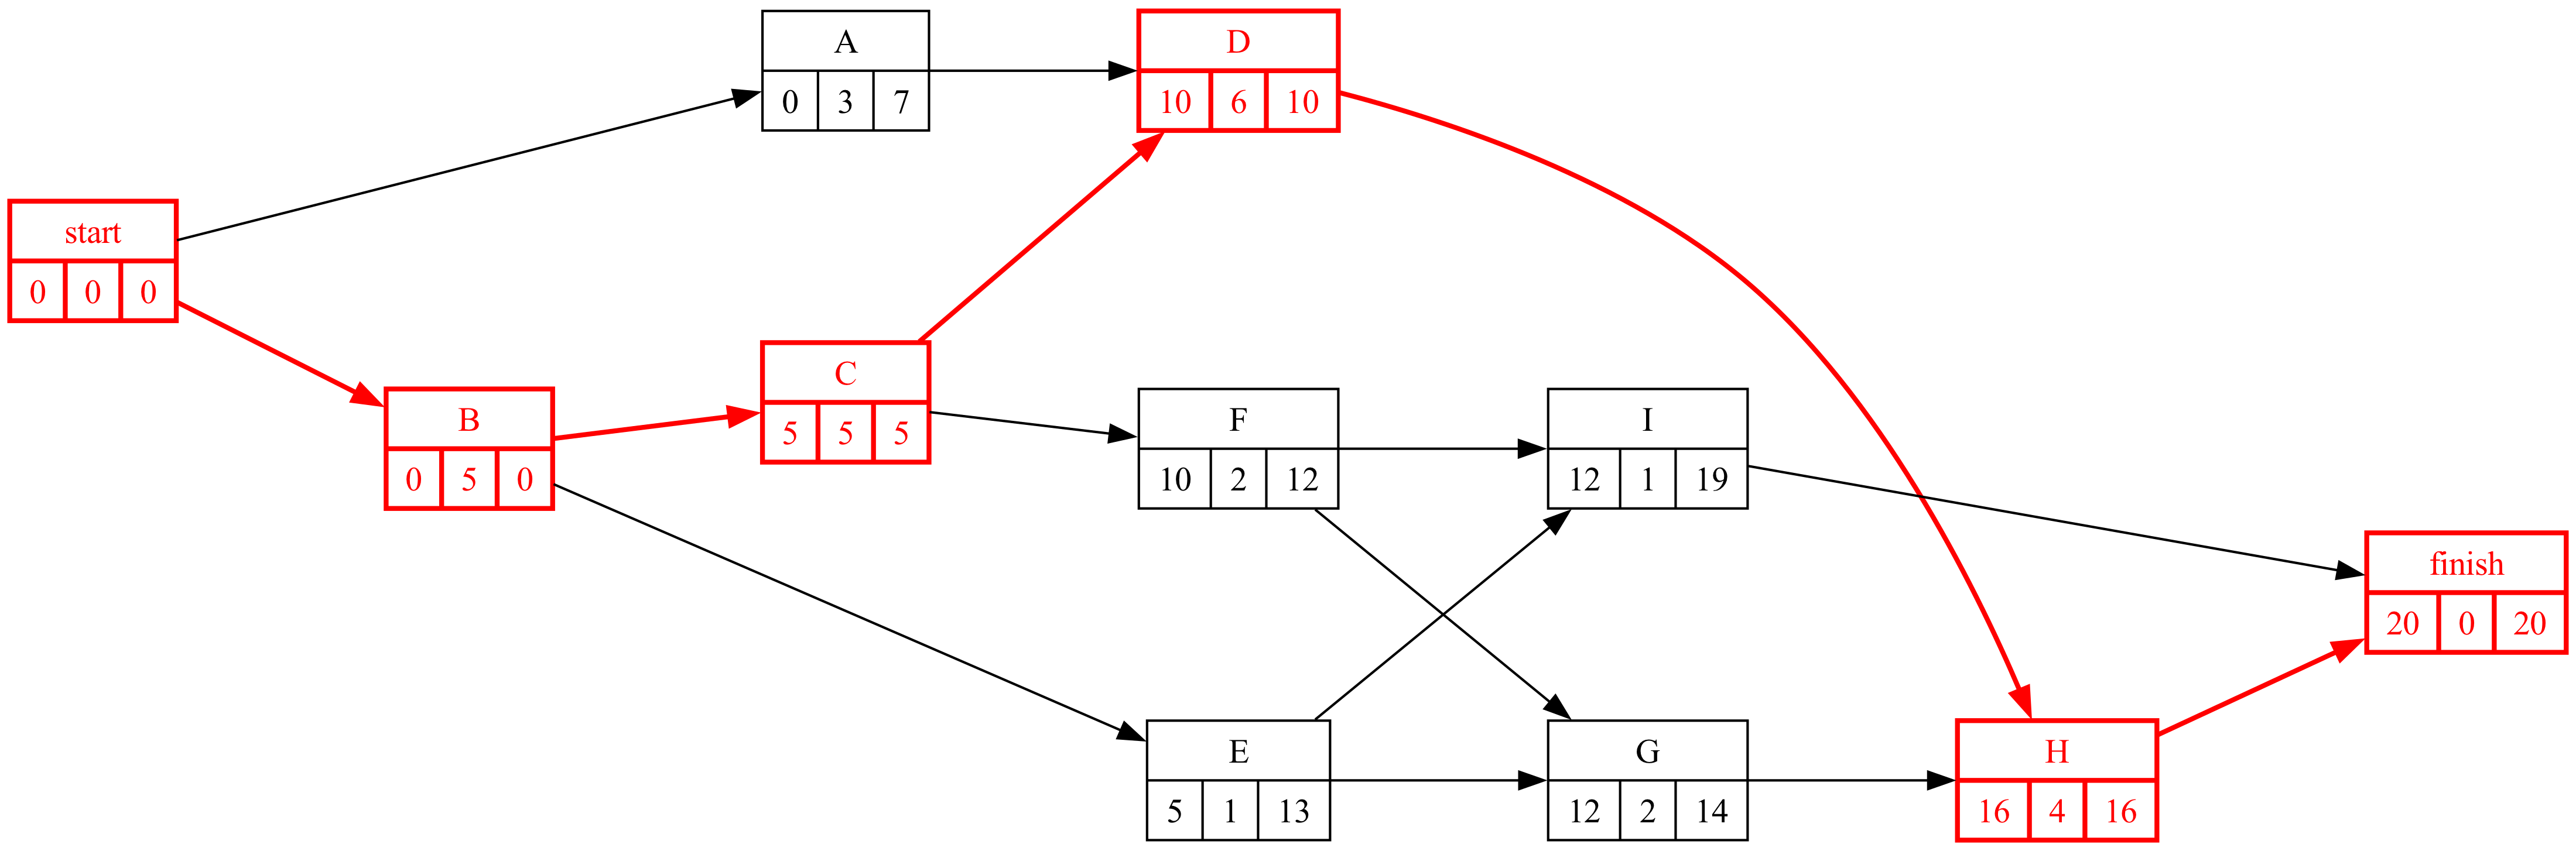

In [8]:
#| fig-cap: "Grafo Roy del proyecto"
#| label: fig-pert
proyecto.roy(durations=datos_proyecto['duration'], ranksep=1.2, nodesep=1.2)

Cálculo de los tiempos mínimos y máximos de los nodos del grafo Roy paso a paso (avance con los botones):

In [7]:
proyecto.display_roy_pasos(datos_proyecto['duration'])

**Tiempos mínimos (hacia delante)**

- $T_{\mathrm{Inicio}} = 0$
- $T_{A} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{B} = 0+0 = 0$ &nbsp; (Inicio)
- $T_{C} = 0+5 = 5$ &nbsp; (B)
- $T_{E} = 0+5 = 5$ &nbsp; (B)
- $T_{D} = \max\{0+3,\ 5+5\} = 10$ &nbsp; (A, C)
- $T_{F} = 5+5 = 10$ &nbsp; (C)
- $T_{G} = \max\{5+1,\ 10+2\} = 12$ &nbsp; (E, F)
- $T_{I} = \max\{5+1,\ 10+2\} = 12$ &nbsp; (E, F)
- $T_{H} = \max\{10+6,\ 12+2\} = 16$ &nbsp; (D, G)
- $T_{\mathrm{Fin}} = \max\{12+1,\ 16+4\} = 20$ &nbsp; (I, H)

**Tiempos máximos (hacia atrás)**

- $T_{\mathrm{Fin}}^{*} = T_{\mathrm{Fin}} = 20$
- $T_{H}^{*} = 20-4 = 16$ &nbsp; (Fin)
- $T_{I}^{*} = 20-1 = 19$ &nbsp; (Fin)
- $T_{G}^{*} = 16-2 = 14$ &nbsp; (H)
- $T_{F}^{*} = \min\{14-2,\ 19-2\} = 12$ &nbsp; (G, I)
- $T_{D}^{*} = 16-6 = 10$ &nbsp; (H)
- $T_{E}^{*} = \min\{14-1,\ 19-1\} = 13$ &nbsp; (G, I)
- $T_{C}^{*} = \min\{10-5,\ 12-5\} = 5$ &nbsp; (D, F)
- $T_{B}^{*} = \min\{5-5,\ 13-5\} = 0$ &nbsp; (C, E)
- $T_{A}^{*} = 10-3 = 7$ &nbsp; (D)
- $T_{\mathrm{Inicio}}^{*} = \min\{7-0,\ 0-0\} = 0$ &nbsp; (A, B)

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Dibuje el diagrama de cargas con inicios más tempranos y obtenga el pico y el exceso de operarios sobre los 5 de plantilla, semana a semana. Nivele las cargas dentro de las holguras (nivelación) y repita el cálculo: ¿cuántos operarios-semana de exceso quedan?  

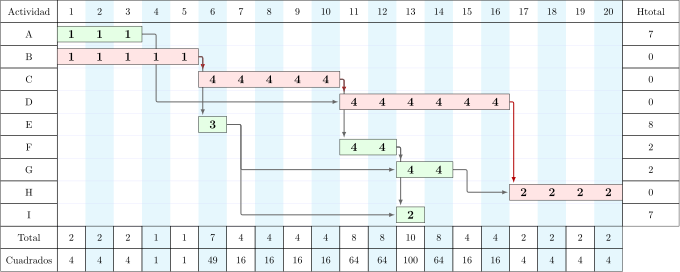

In [10]:
#| fig-cap: "Gantt con inicios más tempranos y carga de operarios"
#| label: fig-ganttCargas
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'resources', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

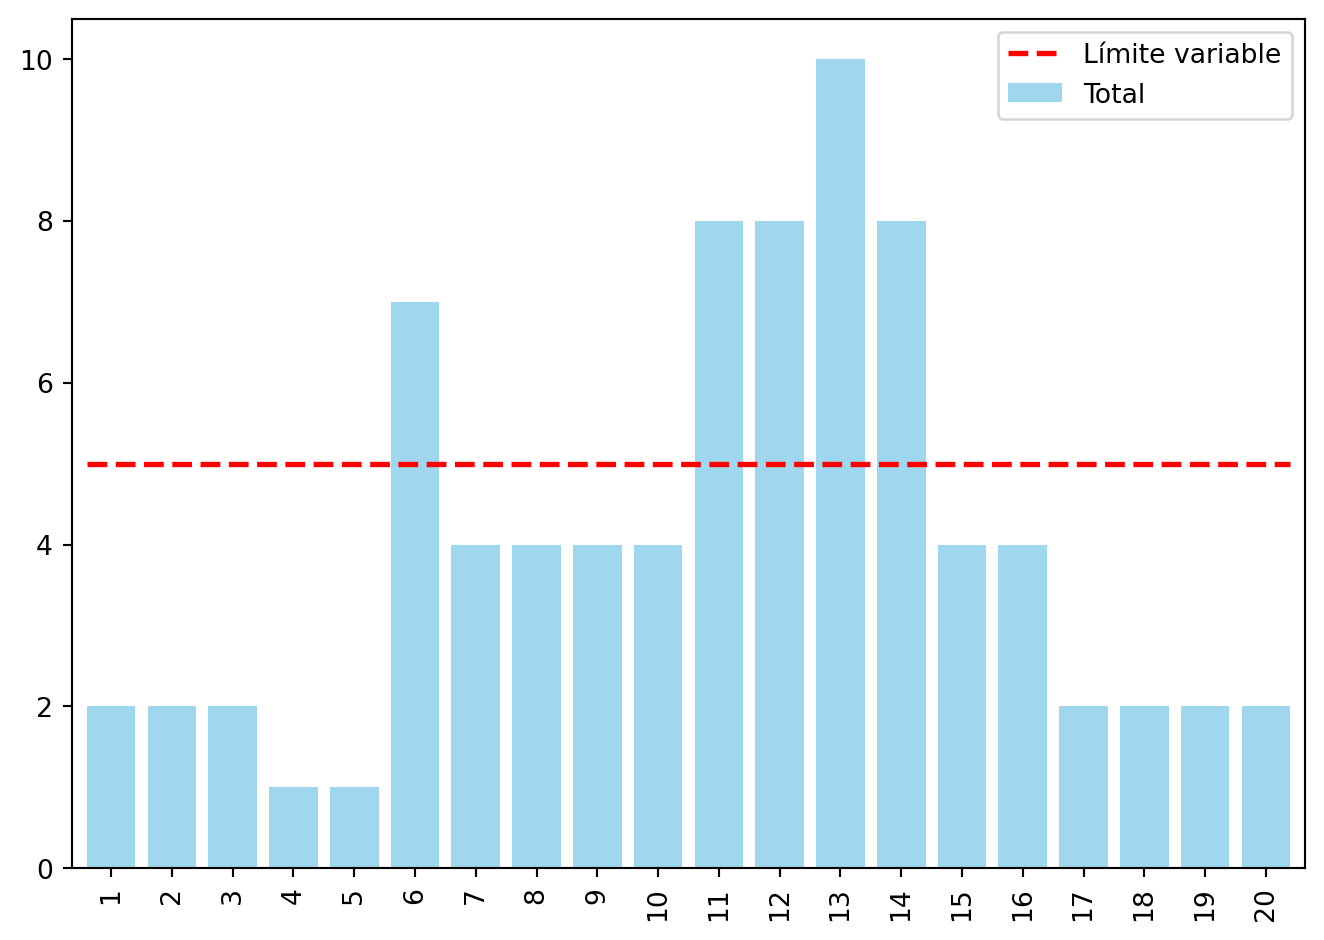

In [11]:
#| fig-cap: "Diagrama de cargas frente a la plantilla"
#| label: fig-cargas
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[plantilla])

In [12]:
#| tbl-cap: "Desplazamientos de la nivelación (suma de cuadrados mínima dentro de las holguras)"
#| label: tbl-nivelacion
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo_niv = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='resources')
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
I,4


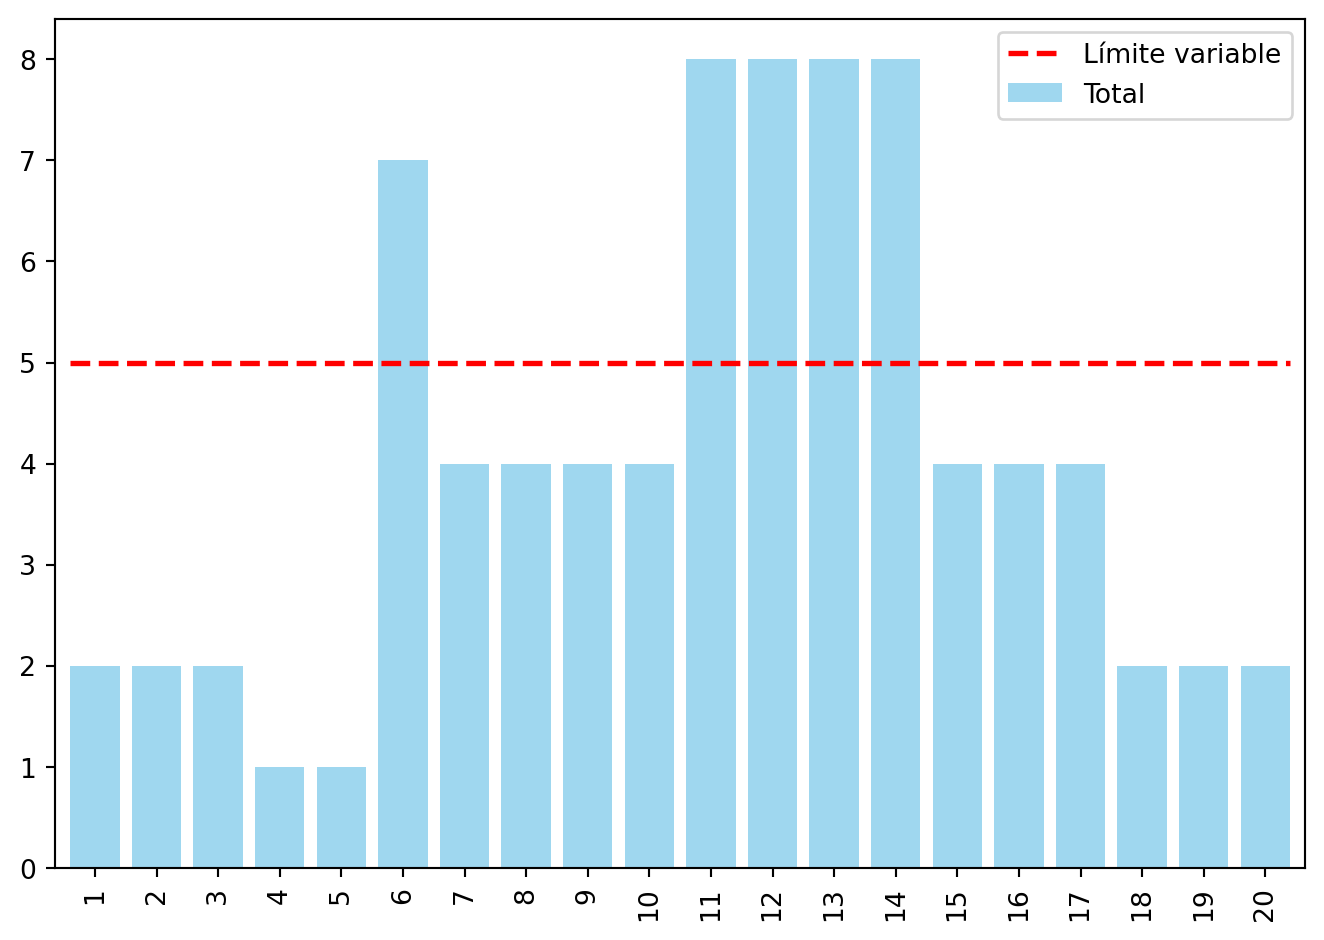

In [13]:
#| fig-cap: "Diagrama de cargas tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=[plantilla])

In [14]:
#| tbl-cap: "Exceso de operarios sobre la plantilla, antes y después de nivelar"
#| label: tbl-exceso
exceso = (cargas - plantilla).clip(lower=0); exceso_niv = (cargas_niveladas - plantilla).clip(lower=0)
tabla = pd.DataFrame({'carga inicial': cargas, 'exceso inicial': exceso, 'carga nivelada': cargas_niveladas, 'exceso nivelado': exceso_niv})
tabla.loc['Total'] = tabla.sum()
display(tabla.astype(int).T)
Markdown(f'''Pico de **{int(cargas.max())}** operarios con inicios más tempranos y **{int(cargas_niveladas.max())}** tras nivelar, frente a {plantilla} de plantilla; el exceso pasa de {int(exceso.sum())} a **{int(exceso_niv.sum())} operarios-semana** sin alargar el proyecto ({duracion} semanas).''')

,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,Total
carga inicial,2,2,2,1,1,7,4,4,4,4,8,8,10,8,4,4,2,2,2,2,81
exceso inicial,0,0,0,0,0,2,0,0,0,0,3,3,5,3,0,0,0,0,0,0,16
carga nivelada,2,2,2,1,1,7,4,4,4,4,8,8,8,8,4,4,4,2,2,2,81
exceso nivelado,0,0,0,0,0,2,0,0,0,0,3,3,3,3,0,0,0,0,0,0,14


Pico de **10** operarios con inicios más tempranos y **8** tras nivelar, frente a 5 de plantilla; el exceso pasa de 16 a **14 operarios-semana** sin alargar el proyecto (20 semanas).

## Apartado 2

In [15]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste de cubrir el exceso (tras nivelar) con la cadena de subcontratas y con una ETT, y el coste de no cubrirlo: asignación con límite de 5 operarios, retraso y penalidad. ¿Cuál es la opción más barata y cuánto vale el «ahorro» de la cadena?  

In [16]:
proyecto_limitado = proyecto.copy()
datos_asignados, gantt_asignado, dibujo_asig = proyecto_limitado.asignar(data=datos_proyecto.copy(), duration_label='duration',
                                                                      resource_label='resources', maximo=[plantilla], report=False, params=GANTT_PARAMS)
duracion_limitada = len(gantt_asignado.data.columns.drop('H_total'))
exceso_total = float(exceso_niv.sum())
opciones = pd.Series({'cadena de subcontratas (ilegal)': exceso_total * coste_cadena,
                      'ETT para el exceso': exceso_total * coste_ett,
                      'sólo plantilla: retraso × penalidad': (duracion_limitada - duracion) * penalidad})
display(opciones.round(1).to_frame('coste (k€)'))
Markdown(f'''Con sólo la plantilla el proyecto dura **{duracion_limitada}** semanas ({duracion_limitada - duracion} de retraso, {(duracion_limitada - duracion) * penalidad} k€ de penalidad). La cadena «ahorra» {exceso_total * (coste_ett - coste_cadena):.1f} k€ frente a la ETT: ese es el precio de los cuatro escalones.''')

,coste (k€)
cadena de subcontratas (ilegal),22.4
ETT para el exceso,36.4
sólo plantilla: retraso × penalidad,40.0


Con sólo la plantilla el proyecto dura **25** semanas (5 de retraso, 40 k€ de penalidad). La cadena «ahorra» 14.0 k€ frente a la ETT: ese es el precio de los cuatro escalones.

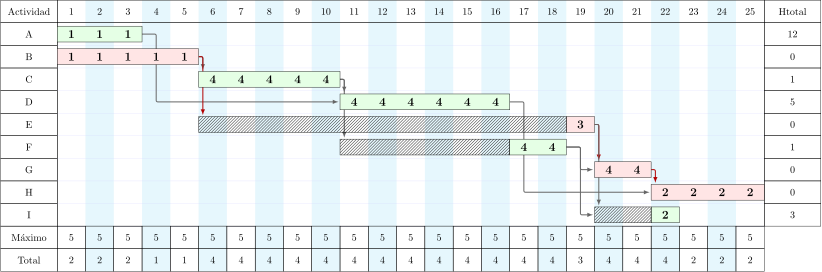

In [17]:
#| fig-cap: "Gantt con asignación limitada a la plantilla"
#| label: fig-ganttAsignado
pinta_tikz(dibujo_asig)

## Apartado 3

In [18]:
display(Markdown(pregunta_3))

3. (B) Según la norma y el criterio de referencia, ¿puede ejecutarse la propuesta del director de producción? ¿Cuál es el último nivel que puede subcontratar y en qué condiciones se admite uno más?  

**Norma.** La Ley 32/2006 limita la cadena: contratista → primer subcontratista → segundo → tercero, y **el tercer subcontratista no puede subcontratar**; los autónomos tampoco (art. 5.2). La propuesta tiene cuatro escalones por debajo del contratista, el último de autónomos: **no puede ejecutarse**. Un nivel más sólo se admite excepcionalmente (caso fortuito, especialización, fuerza mayor), aprobado por la dirección facultativa antes y anotado en el Libro de Subcontratación (art. 5.3); «lo llevan ellos» no exime: el libro es del contratista. **S10.** El «ahorro» de 14.0 k€ sale de las condiciones de quien está al final de la cadena y de los riesgos de seguridad que la ley quiere evitar con el límite: no es una opción de la tabla. **S1.** La cadena no compensa ni minimiza: traslada el impacto a quien no está en la mesa. La respuesta no depende del apartado 2; el cálculo muestra que la opción legal (ETT tras nivelar) cuesta 36 k€ frente a 40 de retraso.

In [19]:
preguntas_test = [
    ('En una obra de construcción, el último nivel que puede subcontratar la ejecución es…', ['el segundo subcontratista (el tercero ya no puede)', 'el tercer subcontratista', 'cualquiera mientras se anote en el Libro de Subcontratación', 'el trabajador autónomo'],
     'Ley 32/2006, art. 5.2.'),
    ('Un nivel adicional de subcontratación se admite…', ['excepcionalmente, con aprobación previa de la dirección facultativa y anotación en el Libro de Subcontratación', 'siempre que el contratista lo autorice', 'nunca', 'si lo pide el cliente'],
     'Art. 5.3: caso fortuito, especialización, complicaciones técnicas o fuerza mayor.'),
    ('Nivelar las cargas dentro de las holguras…', ['reduce el pico sin alargar el proyecto', 'alarga el proyecto', 'reduce la duración', 'elimina siempre el exceso'],
     'Lección 11: la nivelación mueve actividades no críticas.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — subcontratación en cadena')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
print(gift)

$CATEGORY: Sostenibilidad 20 — subcontratación en cadena

::Sostenibilidad 20 — subcontratación en cadena P1::En una obra de construcción, el último nivel que puede subcontratar la ejecución es… {=el segundo subcontratista (el tercero ya no puede) ~el tercer subcontratista ~cualquiera mientras se anote en el Libro de Subcontratación ~el trabajador autónomo ####Ley 32/2006, art. 5.2.}

::Sostenibilidad 20 — subcontratación en cadena P2::Un nivel adicional de subcontratación se admite… {~si lo pide el cliente =excepcionalmente, con aprobación previa de la dirección facultativa y anotación en el Libro de Subcontratación ~nunca ~siempre que el contratista lo autorice ####Art. 5.3: caso fortuito, especialización, complicaciones técnicas o fuerza mayor.}

::Sostenibilidad 20 — subcontratación en cadena P3::Nivelar las cargas dentro de las holguras… {~elimina siempre el exceso =reduce el pico sin alargar el proyecto ~alarga el proyecto ~reduce la duración ####Lección 11: la nivelación mueve a

## Apartado 4

In [20]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al director de producción? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al director de producción: nivelar primero (el exceso baja de 16 a 14 operarios-semana), cubrir el resto con ETT o contratación temporal propia (36 k€) o con una subcontrata de primer nivel con medios propios, y comprobar el 30 % de plantilla indefinida de quien se contrate. Si se quiere subcontratar la especialidad, un escalón, con el libro al día. Prueba de publicidad: ¿explicaría a la Inspección de Trabajo, tras un accidente en la cuadrilla del cuarto escalón, cómo llegó a la obra?